# Minor Project 

In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split

In [2]:
df = pd.read_csv("loan_approval_data.csv")
df

,Applicant_ID,Applicant_Income,Coapplicant_Income,Employment_Status,Age,Marital_Status,Dependents,Credit_Score,Existing_Loans,DTI_Ratio,Savings,Collateral_Value,Loan_Amount,Loan_Term,Loan_Purpose,Property_Area,Education_Level,Gender,Employer_Category,Loan_Approved
0,1.0,17795.0,1387.0,Salaried,51.0,Married,0.0,637.0,4.0,0.53,19403.0,45638.0,16619.0,84.0,Personal,Urban,Not Graduate,Female,Private,No
1,2.0,2860.0,2679.0,Salaried,46.0,Married,3.0,621.0,2.0,0.30,2580.0,49272.0,38687.0,NaN,Car,Semiurban,Graduate,NaN,Private,No
2,3.0,7390.0,2106.0,Salaried,25.0,Single,2.0,674.0,4.0,0.20,13844.0,6908.0,27943.0,72.0,NaN,Urban,NaN,Female,Government,Yes
3,4.0,13964.0,8173.0,Salaried,40.0,Married,2.0,579.0,3.0,0.31,9553.0,10844.0,27819.0,60.0,Business,Rural,Graduate,Female,Government,No
4,5.0,13284.0,4223.0,Self-employed,31.0,Single,2.0,721.0,1.0,0.29,9386.0,37629.0,12741.0,72.0,Car,NaN,Graduate,Male,Private,Yes
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
995,996.0,NaN,9092.0,Salaried,58.0,Married,0.0,557.0,0.0,0.59,5370.0,43563.0,8311.0,72.0,Personal,NaN,Not Graduate,Male,Unemployed,No
996,997.0,3279.0,6356.0,Self-employed,58.0,Married,1.0,646.0,3.0,0.19,NaN,18361.0,22563.0,12.0,Business,Urban,Graduate,Female,Government,No
997,998.0,15192.0,8433.0,Contract,48.0,Single,1.0,666.0,1.0,0.40,8581.0,41335.0,16203.0,24.0,Home,Rural,Graduate,Male,MNC,No
998,999.0,9083.0,7380.0,Unemployed,50.0,Single,1.0,748.0,3.0,0.31,13491.0,8933.0,10290.0,36.0,Personal,Urban,Graduate,Male,Private,Yes


In [3]:
df.describe()
df.info()
df.isnull().sum()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 20 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   Applicant_ID        950 non-null    float64
 1   Applicant_Income    950 non-null    float64
 2   Coapplicant_Income  950 non-null    float64
 3   Employment_Status   950 non-null    object 
 4   Age                 950 non-null    float64
 5   Marital_Status      950 non-null    object 
 6   Dependents          950 non-null    float64
 7   Credit_Score        950 non-null    float64
 8   Existing_Loans      950 non-null    float64
 9   DTI_Ratio           950 non-null    float64
 10  Savings             950 non-null    float64
 11  Collateral_Value    950 non-null    float64
 12  Loan_Amount         950 non-null    float64
 13  Loan_Term           950 non-null    float64
 14  Loan_Purpose        950 non-null    object 
 15  Property_Area       950 non-null    object 
 16  Educati

Applicant_ID          50
Applicant_Income      50
Coapplicant_Income    50
Employment_Status     50
Age                   50
Marital_Status        50
Dependents            50
Credit_Score          50
Existing_Loans        50
DTI_Ratio             50
Savings               50
Collateral_Value      50
Loan_Amount           50
Loan_Term             50
Loan_Purpose          50
Property_Area         50
Education_Level       50
Gender                50
Employer_Category     50
Loan_Approved         50
dtype: int64

# Handle Missing Values

In [4]:
#Catagorical columns

cat_cols = df.select_dtypes(include = "object").columns
cat_cols

Index(['Employment_Status', 'Marital_Status', 'Loan_Purpose', 'Property_Area',
       'Education_Level', 'Gender', 'Employer_Category', 'Loan_Approved'],
      dtype='object')

In [5]:
#numerical values

numer_cols = df.select_dtypes(include = "float64")
numer_cols

,Applicant_ID,Applicant_Income,Coapplicant_Income,Age,Dependents,Credit_Score,Existing_Loans,DTI_Ratio,Savings,Collateral_Value,Loan_Amount,Loan_Term
0,1.0,17795.0,1387.0,51.0,0.0,637.0,4.0,0.53,19403.0,45638.0,16619.0,84.0
1,2.0,2860.0,2679.0,46.0,3.0,621.0,2.0,0.30,2580.0,49272.0,38687.0,NaN
2,3.0,7390.0,2106.0,25.0,2.0,674.0,4.0,0.20,13844.0,6908.0,27943.0,72.0
3,4.0,13964.0,8173.0,40.0,2.0,579.0,3.0,0.31,9553.0,10844.0,27819.0,60.0
4,5.0,13284.0,4223.0,31.0,2.0,721.0,1.0,0.29,9386.0,37629.0,12741.0,72.0
...,...,...,...,...,...,...,...,...,...,...,...,...
995,996.0,NaN,9092.0,58.0,0.0,557.0,0.0,0.59,5370.0,43563.0,8311.0,72.0
996,997.0,3279.0,6356.0,58.0,1.0,646.0,3.0,0.19,NaN,18361.0,22563.0,12.0
997,998.0,15192.0,8433.0,48.0,1.0,666.0,1.0,0.40,8581.0,41335.0,16203.0,24.0
998,999.0,9083.0,7380.0,50.0,1.0,748.0,3.0,0.31,13491.0,8933.0,10290.0,36.0


In [7]:
cat_imp = SimpleImputer(strategy = "most_frequent")
df[cat_cols] = cat_imp.fit_transform(df[cat_cols])

In [8]:
df.sample(20)
df.isnull().sum()

Applicant_ID          50
Applicant_Income      50
Coapplicant_Income    50
Employment_Status      0
Age                   50
Marital_Status         0
Dependents            50
Credit_Score          50
Existing_Loans        50
DTI_Ratio             50
Savings               50
Collateral_Value      50
Loan_Amount           50
Loan_Term             50
Loan_Purpose           0
Property_Area          0
Education_Level        0
Gender                 0
Employer_Category      0
Loan_Approved          0
dtype: int64

# EDA Exploratory Data Analysis

Text(0.5, 1.0, 'is Loan Approved or Not')

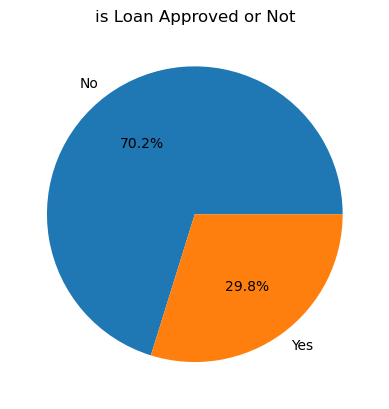

In [9]:
#catagorical features

loan_count = df["Loan_Approved"].value_counts()
plt.pie(loan_count, labels = ["No", "Yes"], autopct = "%1.1f%%")
plt.title("is Loan Approved or Not")

In [ ]:
edu_count = df["Education_Level"].value_counts()
ax = sns.barplot(edu_count)
ax.bar_label(ax.containers[0])

[Text(0, 0, '621'), Text(0, 0, '379')]

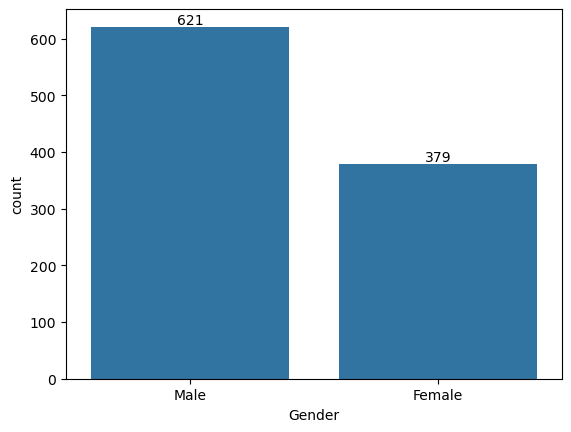

In [11]:
sex_count = df["Gender"].value_counts()
ax = sns.barplot(sex_count)
ax.bar_label(ax.containers[0])

[Text(0, 0, '515'), Text(0, 0, '213'), Text(0, 0, '182'), Text(0, 0, '90')]

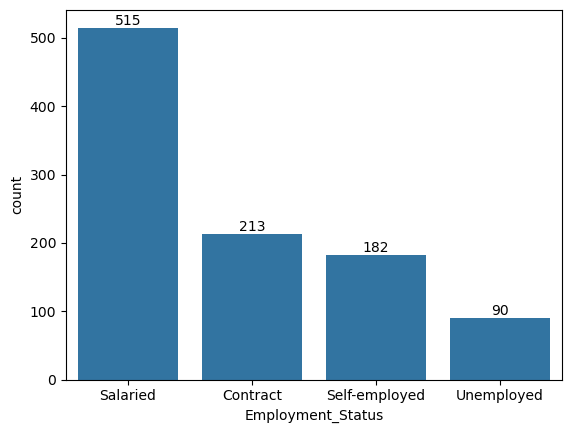

In [12]:
emp_count = df["Employment_Status"].value_counts()
ax = sns.barplot(emp_count)
ax.bar_label(ax.containers[0])

[Text(0, 0, '252'),
 Text(0, 0, '199'),
 Text(0, 0, '190'),
 Text(0, 0, '181'),
 Text(0, 0, '178')]

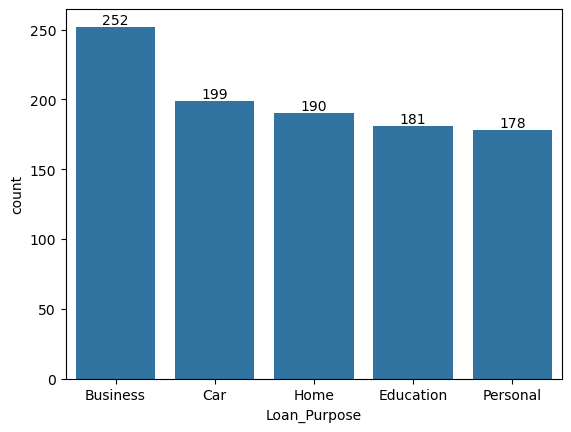

In [13]:
loan_per_count = df["Loan_Purpose"].value_counts()
ax = sns.barplot(loan_per_count)
ax.bar_label(ax.containers[0])

[Text(0, 0, '517'), Text(0, 0, '294'), Text(0, 0, '189')]

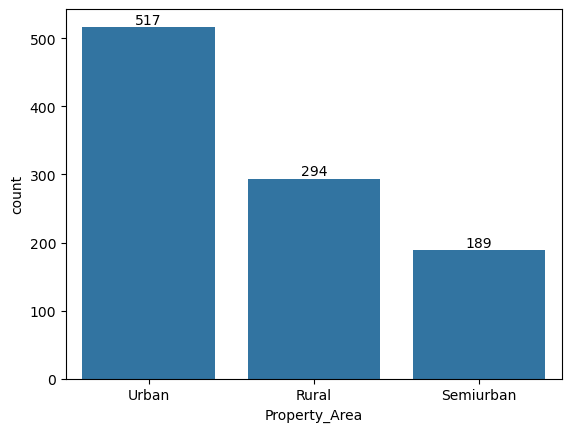

In [14]:
property_count = df["Property_Area"].value_counts()
ax = sns.barplot(property_count)
ax.bar_label(ax.containers[0])

<Axes: xlabel='Applicant_Income', ylabel='Count'>

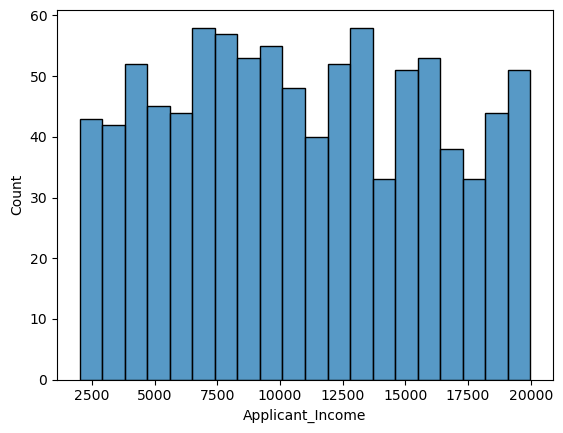

In [15]:
#analyze income

sns.histplot(
    data = df,
    x = "Applicant_Income",
    bins = 20
)

<Axes: xlabel='Coapplicant_Income', ylabel='Count'>

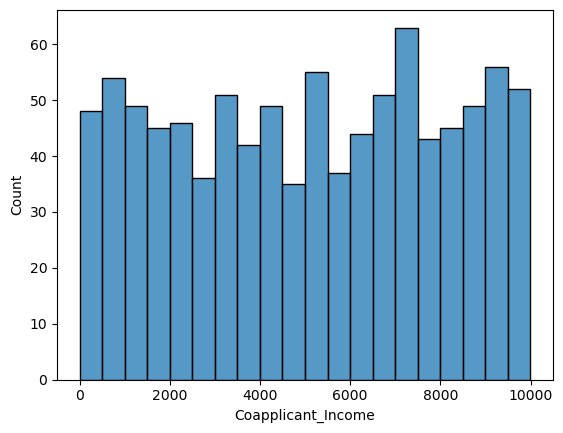

In [16]:
sns.histplot(
    data = df,
    x = "Coapplicant_Income",
    bins = 20
)

<Axes: xlabel='Loan_Approved', ylabel='Applicant_Income'>

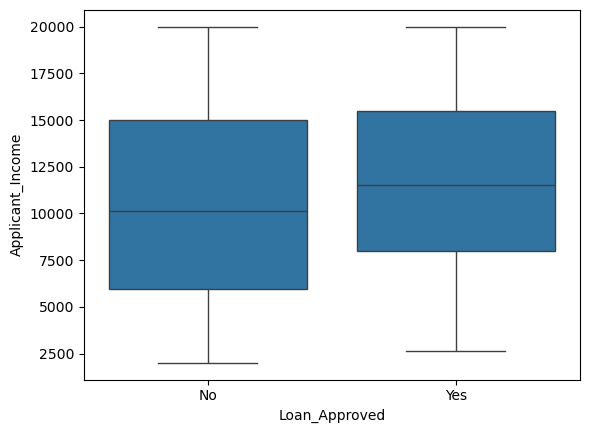

In [17]:
# 1 detect outliers - box plots

sns.boxplot(
    data = df,
    x = "Loan_Approved",
    y = "Applicant_Income"

)

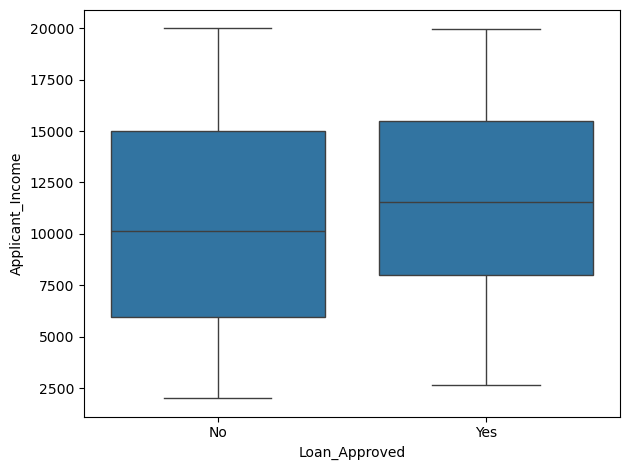

In [18]:
# 2

sns.boxplot(
    data = df,
    x = "Loan_Approved",
    y = "Applicant_Income"

)
plt.tight_layout()

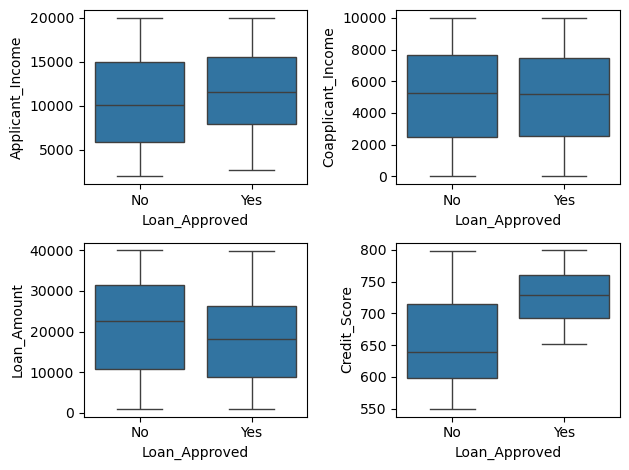

In [19]:
#subplots 

fig, axes = plt.subplots(2, 2)

sns.boxplot(ax = axes[0, 0], data = df, x = "Revenue", y = "Applicant_Income")
sns.boxplot(ax = axes[1, 0], data = df, x = "Revenue", y = "Loan_Amount")
sns.boxplot(ax = axes[0, 1], data = df, x = "Revenue", y = "Coapplicant_Income")
sns.boxplot(ax = axes[1, 1], data = df, x = "Revenue", y = "Credit_Score")

plt.tight_layout()

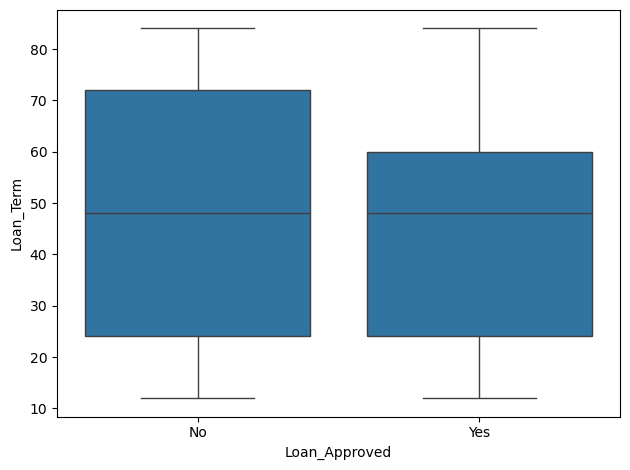

In [20]:
# 3

sns.boxplot(
    data = df,
    x = "Loan_Approved",
    y = "Loan_Term"


)
plt.tight_layout()

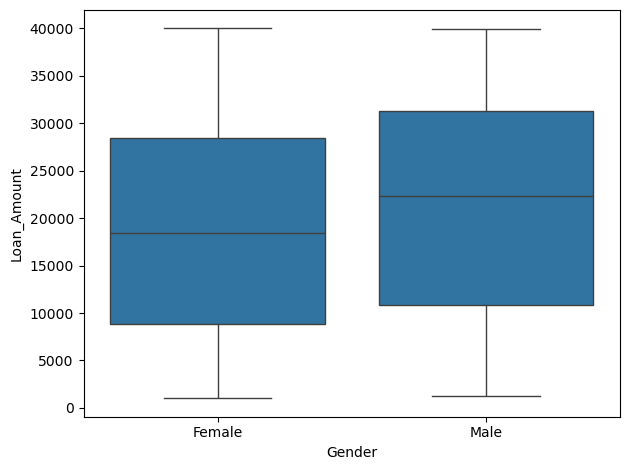

In [21]:
sns.boxplot(
    data = df,
    x = "Gender",
    y = "Loan_Amount"
)
plt.tight_layout()

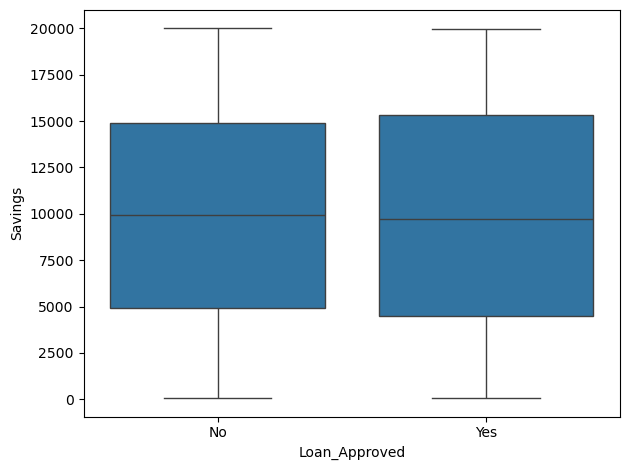

In [22]:
# 4

sns.boxplot(
    data = df,
    x = "Loan_Approved",
    y = "Savings"

)
plt.tight_layout()

<Axes: xlabel='Credit_Score', ylabel='Count'>

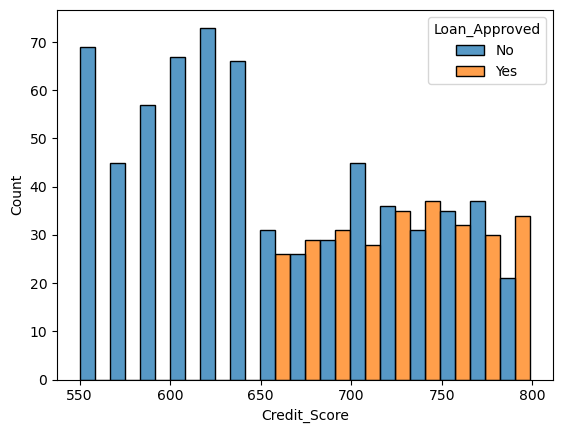

In [23]:
sns.histplot(
    data = df,
    x = "Credit_Score",
    hue = "Loan_Approved",
    bins = 15,
    multiple = "dodge"
)

<Axes: xlabel='Loan_Amount', ylabel='Count'>

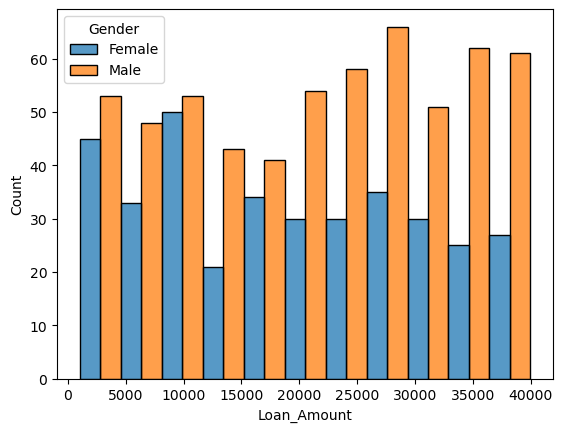

In [24]:
sns.histplot(
    data = df,
    x = "Loan_Amount",
    hue = "Gender",
    multiple = "dodge"
)

In [25]:
# remove applicant ID

df = df.drop("Applicant_ID", axis = 1)
df.head()

,Applicant_Income,Coapplicant_Income,Employment_Status,Age,Marital_Status,Dependents,Credit_Score,Existing_Loans,DTI_Ratio,Savings,Collateral_Value,Loan_Amount,Loan_Term,Loan_Purpose,Property_Area,Education_Level,Gender,Employer_Category,Loan_Approved
0,17795.0,1387.0,Salaried,51.0,Married,0.0,637.0,4.0,0.53,19403.0,45638.0,16619.0,84.0,Personal,Urban,Not Graduate,Female,Private,No
1,2860.0,2679.0,Salaried,46.0,Married,3.0,621.0,2.0,0.30,2580.0,49272.0,38687.0,NaN,Car,Semiurban,Graduate,Male,Private,No
2,7390.0,2106.0,Salaried,25.0,Single,2.0,674.0,4.0,0.20,13844.0,6908.0,27943.0,72.0,Business,Urban,Graduate,Female,Government,Yes
3,13964.0,8173.0,Salaried,40.0,Married,2.0,579.0,3.0,0.31,9553.0,10844.0,27819.0,60.0,Business,Rural,Graduate,Female,Government,No
4,13284.0,4223.0,Self-employed,31.0,Single,2.0,721.0,1.0,0.29,9386.0,37629.0,12741.0,72.0,Car,Urban,Graduate,Male,Private,Yes


# Feature Encoding

In [26]:
#Engineering on Catagorical data

df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 19 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   Applicant_Income    950 non-null    float64
 1   Coapplicant_Income  950 non-null    float64
 2   Employment_Status   1000 non-null   object 
 3   Age                 950 non-null    float64
 4   Marital_Status      1000 non-null   object 
 5   Dependents          950 non-null    float64
 6   Credit_Score        950 non-null    float64
 7   Existing_Loans      950 non-null    float64
 8   DTI_Ratio           950 non-null    float64
 9   Savings             950 non-null    float64
 10  Collateral_Value    950 non-null    float64
 11  Loan_Amount         950 non-null    float64
 12  Loan_Term           950 non-null    float64
 13  Loan_Purpose        1000 non-null   object 
 14  Property_Area       1000 non-null   object 
 15  Education_Level     1000 non-null   object 
 16  Gender 

In [27]:
from sklearn.preprocessing import LabelEncoder, OneHotEncoder

In [28]:
le = LabelEncoder()

df["Education_Level"] = le.fit_transform(df["Education_Level"])
df["Loan_Approved"] = le.fit_transform(df["Loan_Approved"])
df.head()

,Applicant_Income,Coapplicant_Income,Employment_Status,Age,Marital_Status,Dependents,Credit_Score,Existing_Loans,DTI_Ratio,Savings,Collateral_Value,Loan_Amount,Loan_Term,Loan_Purpose,Property_Area,Education_Level,Gender,Employer_Category,Loan_Approved
0,17795.0,1387.0,Salaried,51.0,Married,0.0,637.0,4.0,0.53,19403.0,45638.0,16619.0,84.0,Personal,Urban,1,Female,Private,0
1,2860.0,2679.0,Salaried,46.0,Married,3.0,621.0,2.0,0.30,2580.0,49272.0,38687.0,NaN,Car,Semiurban,0,Male,Private,0
2,7390.0,2106.0,Salaried,25.0,Single,2.0,674.0,4.0,0.20,13844.0,6908.0,27943.0,72.0,Business,Urban,0,Female,Government,1
3,13964.0,8173.0,Salaried,40.0,Married,2.0,579.0,3.0,0.31,9553.0,10844.0,27819.0,60.0,Business,Rural,0,Female,Government,0
4,13284.0,4223.0,Self-employed,31.0,Single,2.0,721.0,1.0,0.29,9386.0,37629.0,12741.0,72.0,Car,Urban,0,Male,Private,1


In [29]:
#one hot encoding

cols = ["Employment_Status", "Marital_Status", "Loan_Purpose", "Property_Area", "Gender", "Employer_Category"]
ohe = OneHotEncoder(drop = "first", sparse_output = False, handle_unknown = "ignore")
encoded = ohe.fit_transform(df[cols])

encoded_df = pd.DataFrame(encoded, columns = ohe.get_feature_names_out(cols), index = df.index)
encoded_df.columns

new_df = pd.concat([df.drop(columns = cols), encoded_df], axis = 1)
new_df.head()

new_df.describe()
new_df.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 28 columns):
 #   Column                           Non-Null Count  Dtype  
---  ------                           --------------  -----  
 0   Applicant_Income                 950 non-null    float64
 1   Coapplicant_Income               950 non-null    float64
 2   Age                              950 non-null    float64
 3   Dependents                       950 non-null    float64
 4   Credit_Score                     950 non-null    float64
 5   Existing_Loans                   950 non-null    float64
 6   DTI_Ratio                        950 non-null    float64
 7   Savings                          950 non-null    float64
 8   Collateral_Value                 950 non-null    float64
 9   Loan_Amount                      950 non-null    float64
 10  Loan_Term                        950 non-null    float64
 11  Education_Level                  1000 non-null   int64  
 12  Loan_Approved        

In [30]:
num_cols = new_df.select_dtypes(include = "number")
corr_matrix = num_cols.corr()
num_cols.corr()["Loan_Approved"].sort_values(ascending = False)

Loan_Approved                      1.000000
Credit_Score                       0.463416
Applicant_Income                   0.122551
Employer_Category_MNC              0.069049
Loan_Purpose_Personal              0.034043
Marital_Status_Single              0.030182
Property_Area_Urban                0.025963
Collateral_Value                   0.022484
Coapplicant_Income                 0.004327
Loan_Purpose_Home                  0.002118
Employment_Status_Self-employed   -0.001337
Employer_Category_Private         -0.003347
Property_Area_Semiurban           -0.012967
Savings                           -0.013802
Loan_Purpose_Education            -0.016684
Employer_Category_Unemployed      -0.021468
Age                               -0.022880
Dependents                        -0.024311
Existing_Loans                    -0.035559
Employer_Category_Government      -0.039187
Employment_Status_Salaried        -0.041428
Employment_Status_Unemployed      -0.044464
Education_Level                 

<Axes: >

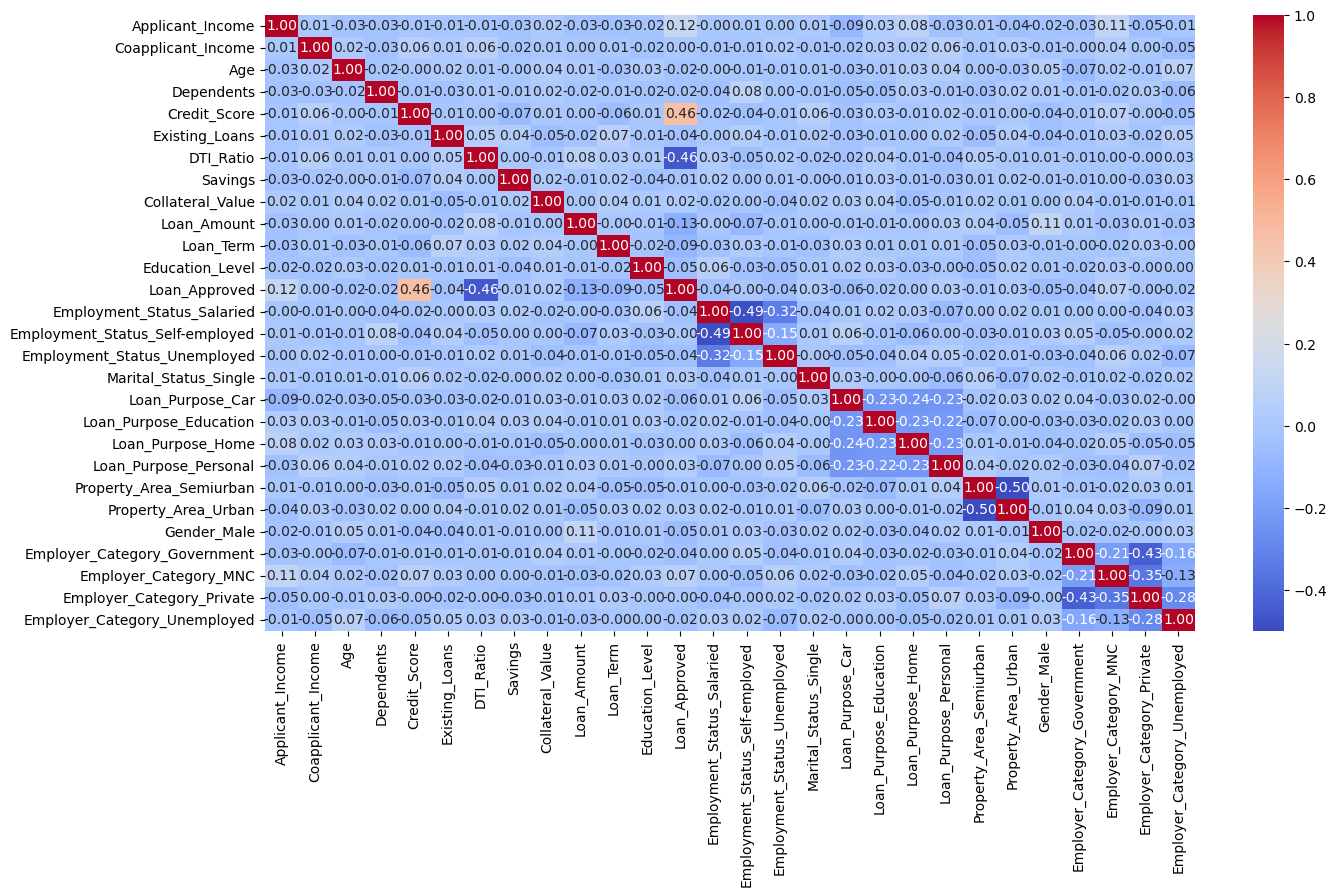

In [31]:
plt.figure(figsize = (15, 8))
sns.heatmap(
    corr_matrix, 
    annot = True,
    fmt = ".2f", 
    cmap = "coolwarm"
)

# Train-Test Data and Feature Scaling

In [32]:
X = new_df.drop("Loan_Approved", axis = 1)
y = new_df["Loan_Approved"]

In [67]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
X_test.head()


,Applicant_Income,Coapplicant_Income,Age,Dependents,Credit_Score,Existing_Loans,DTI_Ratio,Savings,Collateral_Value,Loan_Amount,...,Loan_Purpose_Education,Loan_Purpose_Home,Loan_Purpose_Personal,Property_Area_Semiurban,Property_Area_Urban,Gender_Male,Employer_Category_Government,Employer_Category_MNC,Employer_Category_Private,Employer_Category_Unemployed
521,13023.0,6675.0,53.000000,3.0,628.0,3.0,0.347263,10051.000000,26309.0,22947.000000,...,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,1.0,0.0
737,15917.0,6787.0,42.000000,0.0,588.0,4.0,0.410000,922.000000,13476.0,20522.825263,...,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0
740,7560.0,3530.0,52.000000,3.0,606.0,0.0,0.580000,9940.452632,21795.0,5876.000000,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
660,19022.0,574.0,59.000000,0.0,725.0,4.0,0.410000,1463.000000,44498.0,8433.000000,...,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0
411,4967.0,5797.0,39.971579,3.0,697.0,4.0,0.580000,1095.000000,3017.0,33926.000000,...,0.0,1.0,0.0,0.0,1.0,1.0,1.0,0.0,0.0,0.0


In [68]:
from sklearn.preprocessing import StandardScaler
import numpy as np

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.fit_transform(X_test)


In [46]:
print(X_train_scaled.shape)
print(X_test_scaled.shape)


(800, 27)
(200, 27)


In [51]:
"""y_train.shape
print(y_test.shape)
print(np.isinf(X_train_scaled).sum())
print(type(X_train_scaled))"""

print(X.isnull().sum())

Applicant_Income                   50
Coapplicant_Income                 50
Age                                50
Dependents                         50
Credit_Score                       50
Existing_Loans                     50
DTI_Ratio                          50
Savings                            50
Collateral_Value                   50
Loan_Amount                        50
Loan_Term                          50
Education_Level                     0
Employment_Status_Salaried          0
Employment_Status_Self-employed     0
Employment_Status_Unemployed        0
Marital_Status_Single               0
Loan_Purpose_Car                    0
Loan_Purpose_Education              0
Loan_Purpose_Home                   0
Loan_Purpose_Personal               0
Property_Area_Semiurban             0
Property_Area_Urban                 0
Gender_Male                         0
Employer_Category_Government        0
Employer_Category_MNC               0
Employer_Category_Private           0
Employer_Cat

# Train & Evaluate Model

In [64]:
"""from sklearn.linear_model import LogisticRegression
from sklearn.metrics import confusion_matrix, accuracy_score, precision_score, recall_score, f1_score
try:      
    log_model = LogisticRegression()
    log_model.fit(X_train_scaled, y_train)
except Exception as e:
    print(type(e))
    print(e)
"""

'from sklearn.linear_model import LogisticRegression\nfrom sklearn.metrics import confusion_matrix, accuracy_score, precision_score, recall_score, f1_score\ntry:      \n    log_model = LogisticRegression()\n    log_model.fit(X_train_scaled, y_train)\nexcept Exception as e:\n    print(type(e))\n    print(e)\n'

In [65]:
from sklearn.impute import SimpleImputer

imputer = SimpleImputer(strategy='mean')

X[['Applicant_Income',
   'Coapplicant_Income',
   'Age',
   'Dependents',
   'Credit_Score',
   'Existing_Loans',
   'DTI_Ratio',
   'Savings',
   'Collateral_Value',
   'Loan_Amount',
   'Loan_Term']] = imputer.fit_transform(
    X[['Applicant_Income',
       'Coapplicant_Income',
       'Age',
       'Dependents',
       'Credit_Score',
       'Existing_Loans',
       'DTI_Ratio',
       'Savings',
       'Collateral_Value',
       'Loan_Amount',
       'Loan_Term']]
)

print(X.isnull().sum())

Applicant_Income                   0
Coapplicant_Income                 0
Age                                0
Dependents                         0
Credit_Score                       0
Existing_Loans                     0
DTI_Ratio                          0
Savings                            0
Collateral_Value                   0
Loan_Amount                        0
Loan_Term                          0
Education_Level                    0
Employment_Status_Salaried         0
Employment_Status_Self-employed    0
Employment_Status_Unemployed       0
Marital_Status_Single              0
Loan_Purpose_Car                   0
Loan_Purpose_Education             0
Loan_Purpose_Home                  0
Loan_Purpose_Personal              0
Property_Area_Semiurban            0
Property_Area_Urban                0
Gender_Male                        0
Employer_Category_Government       0
Employer_Category_MNC              0
Employer_Category_Private          0
Employer_Category_Unemployed       0
d

In [69]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import confusion_matrix, accuracy_score, precision_score, recall_score, f1_score   

log_model = LogisticRegression()
log_model.fit(X_train_scaled, y_train)
y_pred = log_model.predict(X_test_scaled)

#evaluation
print("Logistic Regression Model")
print("precision score : ", precision_score(y_test, y_pred))
print("Accuracy score : ", accuracy_score(y_test, y_pred))
print("Recall score : ", recall_score(y_test, y_pred))
print("F1 score : ", f1_score(y_test, y_pred))
print("Confusion Matrix : ", confusion_matrix(y_test, y_pred))

Logistic Regression Model
precision score :  0.8518518518518519
Accuracy score :  0.885
Recall score :  0.7540983606557377
F1 score :  0.8
Confusion Matrix :  [[131   8]
 [ 15  46]]


In [70]:
#knn model 
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import confusion_matrix, accuracy_score, precision_score, recall_score, f1_score

knn_model = KNeighborsClassifier()
knn_model.fit(X_train_scaled, y_train)

#prediction
y_pred = knn_model.predict(X_test_scaled)

#evaluation
print("KNN Model")
print("precision score : ", precision_score(y_test, y_pred))
print("Accuracy score : ", accuracy_score(y_test, y_pred))
print("Recall score : ", recall_score(y_test, y_pred))
print("F1 score : ", f1_score(y_test, y_pred))
print("Confusion Matrix : ", confusion_matrix(y_test, y_pred))


KNN Model
precision score :  0.6086956521739131
Accuracy score :  0.745
Recall score :  0.45901639344262296
F1 score :  0.5233644859813084
Confusion Matrix :  [[121  18]
 [ 33  28]]


In [72]:
#naive bayed model 
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import confusion_matrix, accuracy_score, precision_score, recall_score, f1_score

gnb_model = GaussianNB()
gnb_model.fit(X_train_scaled, y_train)

y_pred = gnb_model.predict(X_test_scaled)

#evaluation
print("Naive BAyes Model")
print("precision score : ", precision_score(y_test, y_pred))
print("Accuracy score : ", accuracy_score(y_test, y_pred))
print("Recall score : ", recall_score(y_test, y_pred))
print("F1 score : ", f1_score(y_test, y_pred))
print("Confusion Matrix : ", confusion_matrix(y_test, y_pred))



Naive BAyes Model
precision score :  0.7777777777777778
Accuracy score :  0.845
Recall score :  0.6885245901639344
F1 score :  0.7304347826086957
Confusion Matrix :  [[127  12]
 [ 19  42]]


# Feature Engineering

In [76]:
new_df["DTI_Ratio_sq"] = new_df["DTI_Ratio"]**2
new_df["Credit_Score_sq"] = new_df["Credit_Score"]**2



X = new_df.drop(columns = ["DTI_Ratio", "Credit_Score", "Loan_Approved"])
y = new_df["Loan_Approved"]


In [77]:
#train test split

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
X_test.head()

,Applicant_Income,Coapplicant_Income,Age,Dependents,Existing_Loans,Savings,Collateral_Value,Loan_Amount,Loan_Term,Education_Level,...,Loan_Purpose_Personal,Property_Area_Semiurban,Property_Area_Urban,Gender_Male,Employer_Category_Government,Employer_Category_MNC,Employer_Category_Private,Employer_Category_Unemployed,DTI_Ratio_sq,Credit_Score_sq
521,13023.0,6675.0,53.0,3.0,3.0,10051.0,26309.0,22947.0,NaN,1,...,0.0,1.0,0.0,1.0,0.0,0.0,1.0,0.0,NaN,394384.0
737,15917.0,6787.0,42.0,0.0,4.0,922.0,13476.0,NaN,60.0,0,...,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.1681,345744.0
740,7560.0,3530.0,52.0,3.0,0.0,NaN,21795.0,5876.0,48.0,1,...,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.3364,367236.0
660,19022.0,574.0,59.0,0.0,4.0,1463.0,44498.0,8433.0,72.0,0,...,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.1681,525625.0
411,4967.0,5797.0,NaN,3.0,4.0,1095.0,3017.0,33926.0,36.0,1,...,0.0,0.0,1.0,1.0,1.0,0.0,0.0,0.0,0.3364,485809.0


In [ ]:

scaler = StandardScaler()

X_train_scaler = scaler.fit_transform(X_train)
X_test_scaler = scaler.fit_transform(X_test)

X_train.head()